# EDA and Results Figures

Exploration only -- all business logic lives in `src/emot/`. This notebook:
1. Explores the MOT17 subset (sequence composition, sample annotated frames).
2. Loads `results/*.json` and renders the comparison figures referenced in `docs/results.md`.

In [1]:
import json
import sys
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent / "src"))
from emot.data.mot17 import load_ground_truth, load_seqinfo

DATA_ROOT = Path("../data/mot17")
RESULTS_DIR = Path("../results")
CACHE_DIR = Path("../cache/detections")
FIGURES_DIR = Path("../docs/figures")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
sequences = sorted(d.name for d in DATA_ROOT.glob("MOT17-*") if d.is_dir())
sequences

['MOT17-02', 'MOT17-04', 'MOT17-11', 'MOT17-13']

## 1. Sequence composition

In [2]:
rows = []
for seq in sequences:
    info = load_seqinfo(DATA_ROOT / seq)
    gt = load_ground_truth(DATA_ROOT / seq)
    rows.append({
        "sequence": seq,
        "n_frames": info.seq_length,
        "frame_rate": info.frame_rate,
        "resolution": f"{info.im_width}x{info.im_height}",
        "n_unique_pedestrians": gt["id"].nunique(),
        "n_gt_boxes": len(gt),
        "mean_boxes_per_frame": len(gt) / info.seq_length,
    })
df = pd.DataFrame(rows)
df

,sequence,n_frames,frame_rate,resolution,n_unique_pedestrians,n_gt_boxes,mean_boxes_per_frame
0,MOT17-02,600,30,1920x1080,62,18581,30.968333
1,MOT17-04,1050,30,1920x1080,83,47557,45.292381
2,MOT17-11,900,30,1920x1080,75,9436,10.484444
3,MOT17-13,750,25,1920x1080,110,11642,15.522667


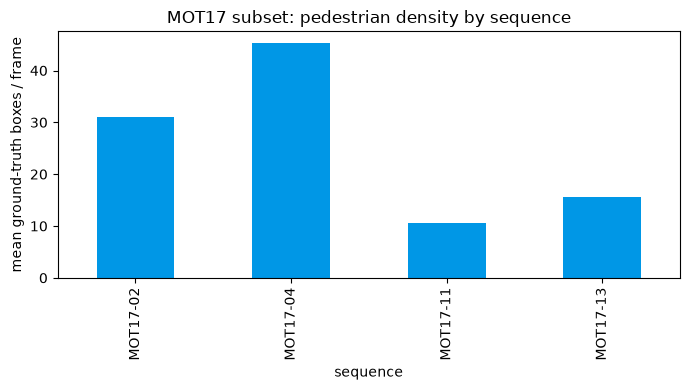

In [3]:
fig, ax = plt.subplots(figsize=(7, 4))
df.set_index("sequence")["mean_boxes_per_frame"].plot.bar(ax=ax, color="#0097e6")
ax.set_ylabel("mean ground-truth boxes / frame")
ax.set_title("MOT17 subset: pedestrian density by sequence")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "sequence_density.png", dpi=150)
plt.show()

## 2. Sample annotated frames per sequence

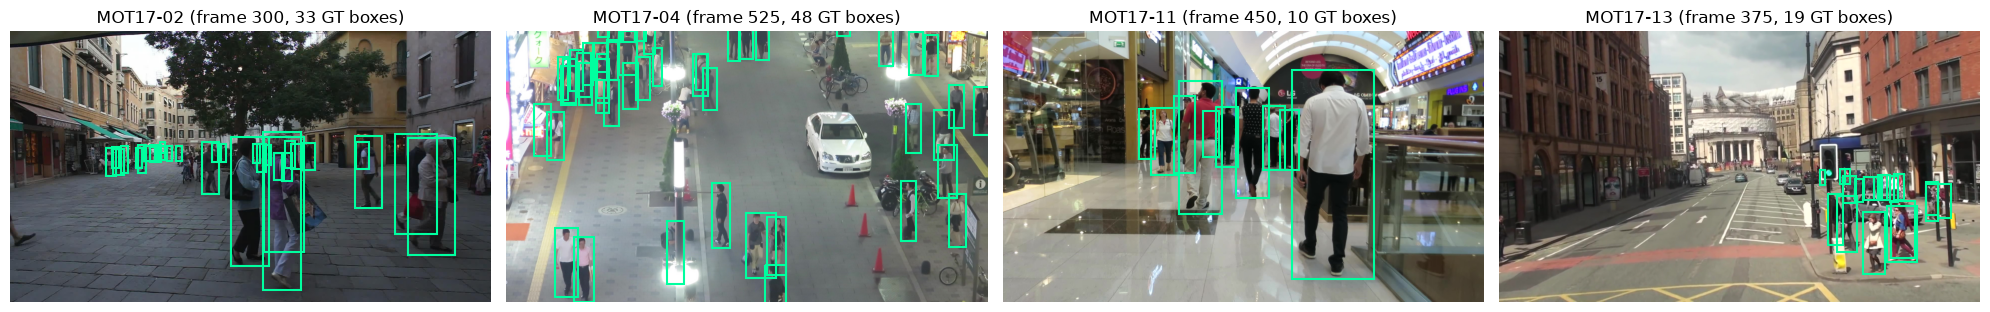

In [4]:
fig, axes = plt.subplots(1, len(sequences), figsize=(5 * len(sequences), 5))
for ax, seq in zip(axes, sequences, strict=True):
    info = load_seqinfo(DATA_ROOT / seq)
    gt = load_ground_truth(DATA_ROOT / seq)
    mid_frame = info.seq_length // 2
    img = cv2.cvtColor(
        cv2.imread(str(DATA_ROOT / seq / "img1" / f"{mid_frame:06d}.jpg")), cv2.COLOR_BGR2RGB
    )
    ax.imshow(img)
    frame_gt = gt[gt["frame"] == mid_frame]
    for _, row in frame_gt.iterrows():
        ax.add_patch(
            plt.Rectangle(
                (row.bb_left, row.bb_top), row.bb_width, row.bb_height,
                fill=False, edgecolor="#00ff9f", linewidth=1.5,
            )
        )
    ax.set_title(f"{seq} (frame {mid_frame}, {len(frame_gt)} GT boxes)")
    ax.axis("off")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "sample_annotated_frames.png", dpi=150)
plt.show()

## 3. Tracking benchmark results (from `results/*.json`)

In [5]:
records = []
for seq_dir in sorted(RESULTS_DIR.glob("MOT17-*")):
    for backbone_dir in sorted(seq_dir.glob("*")):
        for f in sorted(backbone_dir.glob("*.json")):
            records.append(json.loads(f.read_text()))
results_df = pd.DataFrame(records)
results_df

,sequence,backbone,tracker,mota,motp,idf1,num_switches,num_false_positives,num_misses,mostly_tracked,mostly_lost,num_frames,eval_time_sec
0,MOT17-02,yolo11m,bytetrack,0.251278,0.191154,0.346404,49,732,13131,8,37,600,1.145676
1,MOT17-02,yolo11m,deepsort,0.246381,0.197099,0.290929,142,1198,12663,8,35,600,74.691643
2,MOT17-02,yolo11n,bytetrack,0.181799,0.189516,0.263561,59,495,14649,7,42,600,0.998776
3,MOT17-02,yolo11n,deepsort,0.180884,0.207068,0.243784,101,1104,14015,8,41,600,61.234922
4,MOT17-02,yolo11s,bytetrack,0.204402,0.184339,0.330716,43,887,13853,8,39,600,1.106108
5,MOT17-02,yolo11s,deepsort,0.200527,0.192986,0.291682,106,1314,13435,8,37,600,68.484471
6,MOT17-02,yolov8m,bytetrack,0.221786,0.190422,0.330259,51,1147,13262,8,37,600,1.194468
7,MOT17-02,yolov8m,deepsort,0.218287,0.198842,0.290194,124,1821,12580,8,35,600,82.101884
8,MOT17-02,yolov8n,bytetrack,0.169851,0.192471,0.241851,36,786,14603,8,41,600,1.122613
9,MOT17-02,yolov8n,deepsort,0.144072,0.200433,0.255391,95,1544,14265,7,41,600,69.679194


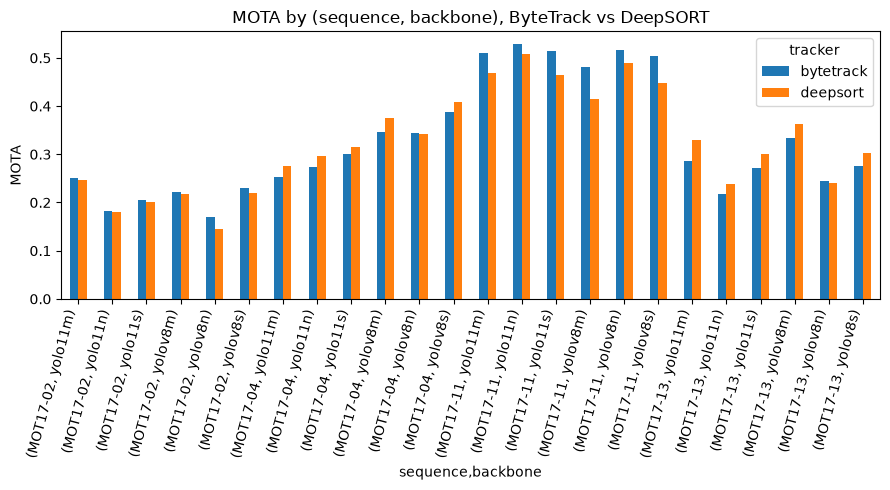

In [6]:
pivot = results_df.pivot_table(index=["sequence", "backbone"], columns="tracker", values="mota")
fig, ax = plt.subplots(figsize=(9, 5))
pivot.plot.bar(ax=ax)
ax.set_ylabel("MOTA")
ax.set_title("MOTA by (sequence, backbone), ByteTrack vs DeepSORT")
plt.xticks(rotation=75, ha="right")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "mota_by_sequence_backbone.png", dpi=150)
plt.show()

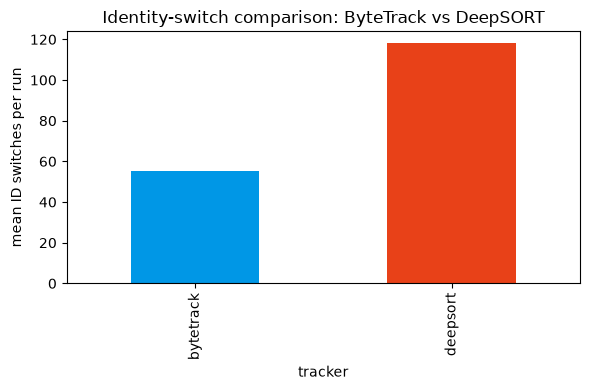

,mean,sum
tracker,,
bytetrack,55.458333,1331
deepsort,118.041667,2833


In [7]:
id_switches = results_df.groupby("tracker")["num_switches"].agg(["mean", "sum"])
fig, ax = plt.subplots(figsize=(6, 4))
id_switches["mean"].plot.bar(ax=ax, color=["#0097e6", "#e84118"])
ax.set_ylabel("mean ID switches per run")
ax.set_title("Identity-switch comparison: ByteTrack vs DeepSORT")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "id_switches_by_tracker.png", dpi=150)
plt.show()
id_switches

## 4. Export benchmark (ONNX / INT8)

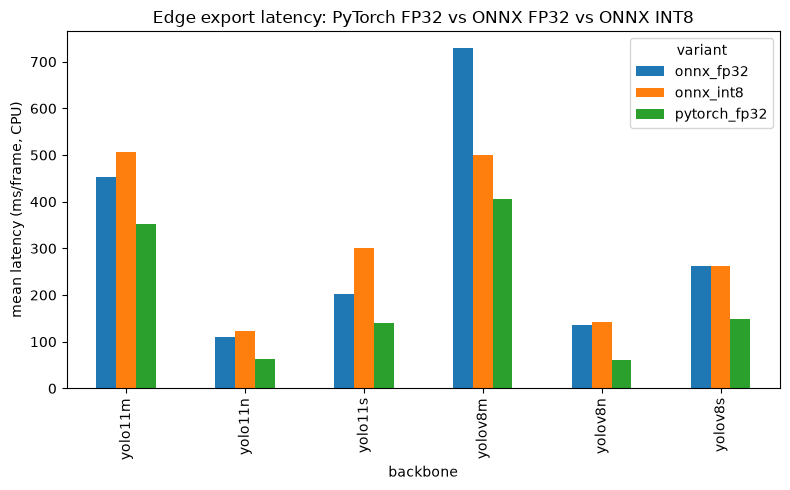

,backbone,variant,file_size_mb,mean_latency_ms,p95_latency_ms,mean_detections_per_frame,mean_iou_vs_reference
0,yolov8n,pytorch_fp32,6.246372,61.733906,65.891475,9.45,NaN
1,yolov8n,onnx_fp32,12.255771,135.587551,161.601063,9.95,0.994255
2,yolov8n,onnx_int8,3.341788,142.917572,183.888304,9.40,0.903651
3,yolov8s,pytorch_fp32,21.542332,148.866041,169.097836,10.45,NaN
4,yolov8s,onnx_fp32,42.791266,262.036140,321.458755,10.40,0.997298
5,yolov8s,onnx_int8,10.989349,263.171846,310.455910,10.95,0.948060
6,yolov8m,pytorch_fp32,49.721607,405.692912,456.929895,12.25,NaN
7,yolov8m,onnx_fp32,99.000549,728.730570,763.083380,12.30,0.994084
8,yolov8m,onnx_int8,25.104118,500.186311,619.403515,11.10,0.872273
9,yolo11n,pytorch_fp32,5.353703,62.675038,66.035505,11.30,NaN


In [8]:
export_path = RESULTS_DIR / "export_benchmark.json"
if export_path.exists():
    export_df = pd.DataFrame(json.loads(export_path.read_text()))
    pivot_export = export_df.pivot(index="backbone", columns="variant", values="mean_latency_ms")
    fig, ax = plt.subplots(figsize=(8, 5))
    pivot_export.plot.bar(ax=ax)
    ax.set_ylabel("mean latency (ms/frame, CPU)")
    ax.set_title("Edge export latency: PyTorch FP32 vs ONNX FP32 vs ONNX INT8")
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / "export_latency.png", dpi=150)
    plt.show()
    display(export_df)
else:
    print("No export benchmark yet -- run src/emot/training/run_export_benchmark.py")